# Exploratory Analysis: NYC 311 Service Requests, Staten Island, 2025

This notebook explores the **real** extract loaded by the pipeline (`python -m src.pipeline --full-refresh`).
It reads the original raw file (unchanged API output) and the PostgreSQL staging and analytics layers.
Every figure below is computed from that data.

In [1]:
import sys, glob, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src.database.db import get_engine, read_df
from src.ingestion.socrata_client import read_raw_file
sns.set_theme(style='whitegrid', palette=['#1F4E79', '#E07B39', '#5B9BD5', '#70AD47', '#A5A5A5'])
pd.set_option('display.width', 160, 'display.max_columns', 30)
engine = get_engine()
conn = engine.connect()

## 1. Dataset overview
The original file is the newest full-refresh extract in `data/raw/`.

In [2]:
raw_path = sorted(glob.glob(str(ROOT / 'data/raw/nyc311_full-refresh_*.jsonl.gz')))[-1]
raw = pd.DataFrame(read_raw_file(Path(raw_path)))
print(Path(raw_path).name, '| rows:', len(raw), '| columns:', raw.shape[1])
raw.head(3).T

nyc311_full-refresh_20261125T183339.jsonl.gz | rows: 134348 | columns: 20


,0,1,2
unique_key,42306171,42306172,42306247
created_date,2025-10-31T08:45:01.000,2025-10-31T14:09:44.000,2025-10-31T11:19:18.000
closed_date,2025-10-31T08:45:01.000,2025-10-31T14:09:44.000,2025-10-31T11:19:18.000
agency,DOB,DOB,DOB
agency_name,Department of Buildings,Department of Buildings,Department of Buildings
complaint_type,Construction Safety Enforcement,Construction Safety Enforcement,Construction Safety Enforcement
descriptor,CSC - Monitoring Tracking,CSC - Monitoring Tracking,CSC - Monitoring Tracking
status,Closed,Closed,Closed
resolution_description,The Department of Buildings reviewed this comp...,The Department of Buildings reviewed this comp...,The Department of Buildings reviewed this comp...
resolution_action_updated_date,2025-10-31T00:00:00.000,2025-10-31T00:00:00.000,2025-10-31T00:00:00.000


## 2. Schema inspection
The API returns every field as text; staging applies types. Below are the staging types and an example of the API's original values.

In [3]:
stg = read_df(conn, "SELECT * FROM analytics.v_snapshot_raw")   # current source snapshot only (no superseded history)
pd.DataFrame({'dtype': stg.dtypes.astype(str), 'example': stg.iloc[0]}).head(26)

,dtype,example
record_hash,object,70e9ee943ff0998216ac31615ecc7b24
unique_key,object,42306171
created_at,datetime64[ns],2025-10-31 08:45:01
closed_at,datetime64[ns],2025-10-31 08:45:01
due_at,datetime64[ns],NaT
resolution_updated_at,datetime64[ns],2025-10-31 00:00:00
agency,object,DOB
agency_name,object,Department of Buildings
complaint_type,object,Construction Safety Enforcement
descriptor,object,CSC - Monitoring Tracking


## 3. Descriptive statistics

In [4]:
fact = read_df(conn, "SELECT * FROM analytics.v_service_requests")
fact['resolution_days'] = fact['resolution_days'].astype(float)
print(fact['status'].value_counts().to_string())
fact['resolution_days'].describe(percentiles=[.25, .5, .75, .9, .99]).round(2)

status
Closed         132019
In Progress      1773
Pending           233
Open              217
Assigned           99
Started             7


count    131951.00
mean         11.49
std          45.03
min           0.00
25%           0.06
50%           0.64
75%           3.72
90%          13.97
99%         279.84
max         645.92
Name: resolution_days, dtype: float64

## 4. Missing-value analysis
Missing values are only problems where a field is required. `closed_at` is legitimately empty for open requests; `due_at` is optional and almost never populated in this extract, so **official SLA compliance cannot be computed**.

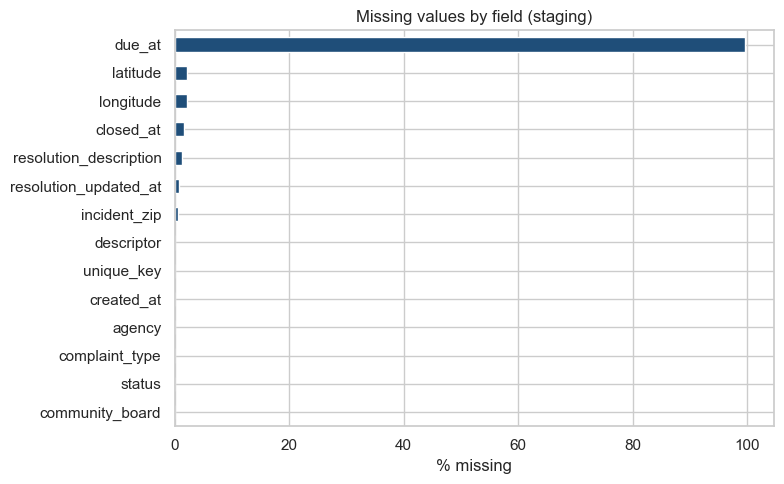

closed status but no closed date: 62 | open with no closed date (legitimate): 2138


In [5]:
cols = ['unique_key','created_at','closed_at','due_at','resolution_updated_at','agency','complaint_type','descriptor',
        'status','resolution_description','incident_zip','latitude','longitude','community_board']
miss = (stg[cols].isna().mean() * 100).sort_values(ascending=False).round(3)
ax = miss.plot.barh(figsize=(8, 5), color='#1F4E79'); ax.set_xlabel('% missing'); ax.set_title('Missing values by field (staging)')
ax.invert_yaxis(); plt.tight_layout(); plt.show()
closed_missing = stg[stg['status'].eq('Closed') & stg['closed_at'].isna()]
open_missing = stg[~stg['status'].eq('Closed') & stg['closed_at'].isna()]
print('closed status but no closed date:', len(closed_missing), '| open with no closed date (legitimate):', len(open_missing))

## 5. Duplicate analysis

In [6]:
print('duplicate unique_key in raw extract :', raw['unique_key'].duplicated().sum())
print('exact duplicate rows in raw extract :', raw.drop(columns=[':updated_at']).duplicated().sum())
print('raw rows / distinct keys in database:', read_df(conn, 'SELECT count(*) n, count(DISTINCT unique_key) k FROM raw.service_requests').values.tolist())

duplicate unique_key in raw extract : 0


exact duplicate rows in raw extract : 0
raw rows / distinct keys in database: [[134348, 134348]]


No duplicates exist in this extract. The dedup rules (DQ001/DQ002) still matter operationally: incremental refreshes re-read an overlap window, and changed records arrive as new versions.

## 6. Request volume trends

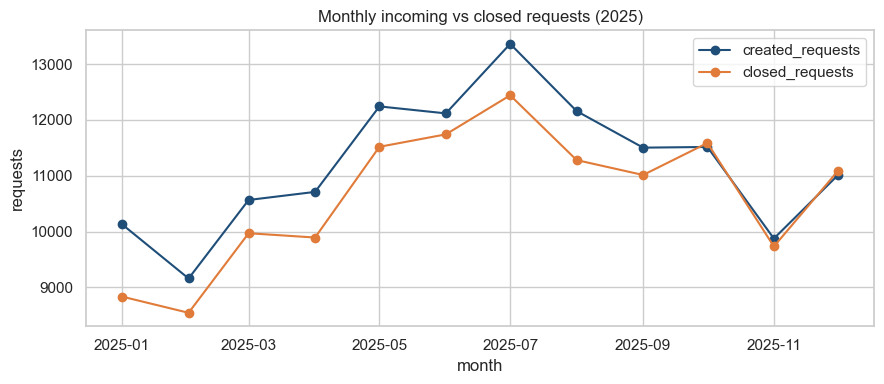

,month,created_requests,closed_requests,net
0,2025-01-01,10128,8833,1295
1,2025-02-01,9158,8543,615
2,2025-03-01,10565,9969,596
3,2025-04-01,10710,9892,818
4,2025-05-01,12242,11518,724
5,2025-06-01,12117,11741,376
6,2025-07-01,13363,12441,922
7,2025-08-01,12158,11280,878
8,2025-09-01,11503,11013,490
9,2025-10-01,11515,11586,-71


In [7]:
vol = read_df(conn, "SELECT * FROM analytics.v_monthly_volume WHERE month < '2026-01-01' ORDER BY month")
ax = vol.plot(x='month', y=['created_requests', 'closed_requests'], figsize=(9, 4), marker='o')
ax.set_title('Monthly incoming vs closed requests (2025)'); ax.set_ylabel('requests'); plt.tight_layout(); plt.show()
vol.assign(net=vol.created_requests - vol.closed_requests)

## 7. Resolution duration distribution
The distribution is extremely right-skewed: most requests close within a day, but a long tail lasts months. This is why median and P90 are reported alongside the mean.

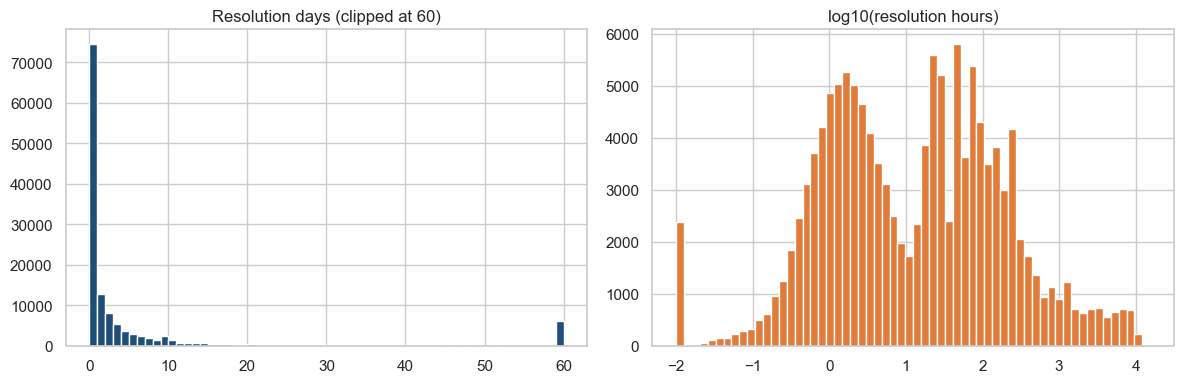

mean=11.49d  median=0.64d  p90=13.97d


In [8]:
d = fact.loc[fact['include_in_resolution_metrics'], 'resolution_days']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(d.clip(upper=60), bins=60, color='#1F4E79'); axes[0].set_title('Resolution days (clipped at 60)')
axes[1].hist(np.log10(d * 24 + 1e-2), bins=60, color='#E07B39'); axes[1].set_title('log10(resolution hours)')
plt.tight_layout(); plt.show()
print(f"mean={d.mean():.2f}d  median={d.median():.2f}d  p90={d.quantile(.9):.2f}d")

## 8. Outlier investigation
Durations over 365 days (rule DQ013) and negative durations (DQ006).

In [9]:
s = stg.assign(days=(stg.closed_at - stg.created_at).dt.total_seconds() / 86400)
print('> 365 days by agency/type:'); print(s[s.days > 365].groupby(['agency', 'complaint_type']).size().sort_values(ascending=False).head(8).to_string())
neg = s[s.days < 0][['unique_key','agency','complaint_type','status','created_at','closed_at','days']]
print('\nnegative durations:', len(neg)); neg.sort_values('days').head(24)

> 365 days by agency/type:
agency  complaint_type               
DPR     Dead/Dying Tree                  90
        Root/Sewer/Sidewalk Condition    79
        Damaged Tree                     76
        Overgrown Tree/Branches          64
DOB     General Construction/Plumbing    47
        Building/Use                     46
DOT     Street Light Condition           16
EDC     Noise - Helicopter               15

negative durations: 24


,unique_key,agency,complaint_type,status,created_at,closed_at,days
77036,65725802,DOT,Street Light Condition,Pending,2025-08-01 15:35:00,2025-07-31 15:27:00,-1.005556
9168,63924345,DOT,Street Light Condition,Pending,2025-01-29 13:33:00,2025-01-28 13:26:00,-1.004861
88828,66026371,DOT,Street Light Condition,Pending,2025-09-02 07:53:00,2025-09-01 07:49:00,-1.002778
12943,64036923,DOT,Street Light Condition,Pending,2025-02-10 15:49:00,2025-02-09 15:47:00,-1.001389
104939,66487551,DOT,Street Light Condition,Pending,2025-10-15 15:21:00,2025-10-14 15:19:00,-1.001389
9099,63922507,DOT,Street Light Condition,Pending,2025-01-29 13:24:00,2025-01-28 13:23:00,-1.000694
121335,67013404,DOT,Street Light Condition,Pending,2025-12-01 07:20:00,2025-11-30 07:19:00,-1.000694
103283,66434141,DOT,Street Light Condition,Pending,2025-10-10 14:47:00,2025-10-09 14:46:00,-1.000694
102317,66405059,DOT,Street Light Condition,Pending,2025-10-07 14:22:00,2025-10-06 14:21:00,-1.000694
101011,66362892,DOT,Street Light Condition,Pending,2025-10-03 11:26:00,2025-10-02 11:25:00,-1.000694


Two clear patterns in the negative durations:
* **NYPD noise complaints on 2025-11-02 between 01:00 and 02:00.** That is the hour US clocks fell back from EDT to EST. Timestamps are published as local "floating" times with no offset, so an event logged in the second 01:xx can appear to come before one logged in the first. *Confirmed by timing; the internal system's storage format cannot be verified.*
* **DOT Street Light Condition, status Pending, closed almost exactly 24 hours before creation.** This is a systematic one-day offset on records still in progress, consistent with the closed date being carried over from a linked or prior record. *Hypothesis: it cannot be confirmed without DOT's source system.*

## 9. Agency comparisons

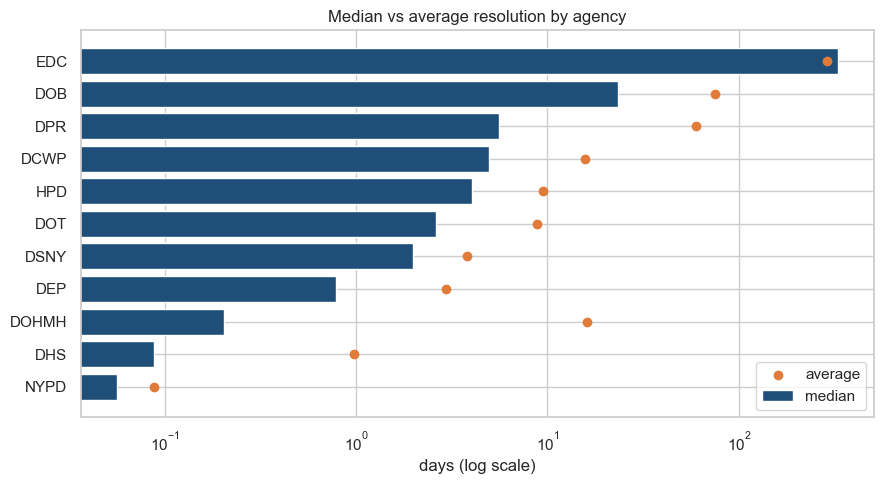

,agency_code,total_requests,resolution_rate,median_resolution_hours,avg_resolution_hours,within_target_rate
0,NYPD,48108,1.0000,1.35,2.12,1.0000
1,DHS,369,1.0000,2.11,23.42,0.9739
2,DOHMH,3497,0.9325,4.88,384.54,0.6765
3,DEP,12324,0.9879,18.80,71.18,0.9038
4,DSNY,23878,0.9806,47.76,90.97,0.9176
5,DOT,16829,0.9829,62.70,211.23,0.6661
6,HPD,11903,0.9944,97.28,226.92,0.6461
7,DCWP,635,0.9984,118.59,375.77,0.5521
8,DPR,11729,0.9279,133.75,1436.90,0.5459
9,DOB,4456,0.9654,559.67,1803.52,0.3403


In [10]:
ag = read_df(conn, "SELECT * FROM analytics.v_agency_performance WHERE total_requests >= 300 ORDER BY median_resolution_hours")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ag.agency_code, ag.median_resolution_hours.astype(float) / 24, color='#1F4E79', label='median')
ax.scatter(ag.avg_resolution_hours.astype(float) / 24, ag.agency_code, color='#E07B39', zorder=3, label='average')
ax.set_xscale('log'); ax.set_xlabel('days (log scale)'); ax.set_title('Median vs average resolution by agency'); ax.legend()
plt.tight_layout(); plt.show()
ag[['agency_code','total_requests','resolution_rate','median_resolution_hours','avg_resolution_hours','within_target_rate']]

## 10. Data quality findings

In [11]:
rs = read_df(conn, "SELECT rule_id, rule_name, severity, treatment, issues, affected_records FROM ops.v_dq_rule_summary ORDER BY issues DESC")
iss = read_df(conn, "SELECT * FROM ops.v_dq_issues_latest")
dqs = read_df(conn, "SELECT * FROM ops.v_dq_run_summary").iloc[0]
print(f"record level : {dqs.records_affected:,} of {dqs.records_inspected:,} rows affected, pass rate {dqs.record_pass_rate:.3%}")
print(f"request level: {dqs.requests_affected:,} of {dqs.requests_inspected:,} requests affected, pass rate {dqs.request_pass_rate:.3%}")
print(f"individual issues: {len(iss):,}")
pd.crosstab(iss.agency, iss.rule_id).loc[lambda t: t.sum(axis=1).sort_values(ascending=False).index]

record level : 1,479 of 134,348 rows affected, pass rate 98.899%
request level: 1,479 of 134,348 requests affected, pass rate 98.899%
individual issues: 1,508


rule_id,DQ005,DQ006,DQ011,DQ013,DQ014,DQ015
agency,,,,,,
DOT,0,21,29,18,297,3
DPR,0,0,0,313,0,0
DSNY,0,0,0,1,272,0
DOB,0,0,154,104,0,0
NYPD,0,3,0,0,153,35
DHS,62,0,0,0,1,1
EDC,0,0,0,15,0,0
TLC,0,0,0,2,8,0
HPD,0,0,6,0,0,2


In [12]:
precision = stg.assign(midnight=stg.closed_at.dt.time.astype(str).eq('00:00:00'),
                       zero=stg.closed_at.eq(stg.created_at)).groupby('agency')[['midnight','zero']].mean().round(3)
precision.sort_values('midnight', ascending=False).head(6)

,midnight,zero
agency,,
DOB,0.894,0.106
DSNY,0.010,0.000
DEP,0.003,0.013
DOT,0.002,0.022
DCWP,0.000,0.000
DHS,0.000,0.000


**Timestamp precision (an observation, not a rule violation).** Most DOB closures are stamped exactly at midnight, so DOB closure times are recorded to the day only. DOHMH has a high share of zero-duration closures, where the request was closed at the second it was created. Both affect how comparable agency resolution times are. They are documented in `reports/root_cause_analysis.md` rather than "fixed".

## 11. Raw vs cleaned comparison

In [13]:
read_df(conn, 'SELECT metric, unit, raw_value, clean_value, abs_diff, pct_diff FROM analytics.v_raw_vs_clean ORDER BY ord')

,metric,unit,raw_value,clean_value,abs_diff,pct_diff
0,Total requests,count,134348.0000,134348.0000,0.0000,0.000
1,Closed requests,count,132019.0000,132019.0000,0.0000,0.000
2,Open requests,count,2329.0000,2329.0000,0.0000,0.000
3,Resolution rate (percent),percent,98.2664,98.2664,0.0000,0.000
4,Average resolution (hours),hours,275.8118,275.6785,-0.1333,-0.048
5,Median resolution (hours),hours,15.2342,15.2970,0.0628,0.412
6,P90 resolution (hours),hours,335.9721,335.3760,-0.5961,-0.177
7,Within 7-day analytical target (percent),percent,83.0221,83.0240,0.0019,0.002


In [14]:
read_df(conn, 'SELECT * FROM analytics.v_raw_vs_clean_agency WHERE avg_abs_diff <> 0')

,agency_code,raw_n,clean_n,raw_avg_hours,clean_avg_hours,avg_abs_diff,avg_pct_diff,raw_median_hours,clean_median_hours,median_pct_diff
0,DOB,4456,4302,1757.13,1803.52,46.40,2.641,512.43,559.67,9.219
1,DOT,16571,16539,210.80,211.23,0.43,0.202,62.32,62.70,0.614
2,HPD,11842,11836,226.85,226.92,0.08,0.033,97.26,97.28,0.013


## 12. Business conclusions
Computed below from the data; the narrative lives in `reports/executive_summary.md`.

In [15]:
k = read_df(conn, 'SELECT * FROM analytics.v_kpi_summary').iloc[0]
bk = read_df(conn, "SELECT agency_code, backlog FROM analytics.v_backlog_monthly WHERE month_end = '2025-12-31' ORDER BY backlog DESC LIMIT 3")
print(f"1. {int(k.total_requests):,} requests; {k.resolution_rate:.1%} closed; median {float(k.median_resolution_hours):.1f} h vs average {float(k.avg_resolution_hours):.1f} h.")
print(f"2. {k.within_target_rate:.1%} of eligible requests resolved within the 7-day ANALYTICAL target (not an official SLA).")
print('3. Largest month-end backlog at 2025-12-31:', ', '.join(f'{r.agency_code} ({r.backlog})' for r in bk.itertuples()))
rvc = read_df(conn, 'SELECT * FROM analytics.v_raw_vs_clean')
dob = read_df(conn, "SELECT median_pct_diff FROM analytics.v_raw_vs_clean_agency WHERE agency_code = 'DOB'").iloc[0, 0]
print(f"4. Request-level DQ pass rate {dqs.request_pass_rate:.2%}; largest headline change after cleaning "
      f"{rvc.pct_diff.abs().max():.2f}%; DOB median change {dob:+.1f}%.")
conn.close()

1. 134,348 requests; 98.3% closed; median 15.3 h vs average 275.7 h.
2. 83.0% of eligible requests resolved within the 7-day ANALYTICAL target (not an official SLA).
3. Largest month-end backlog at 2025-12-31: DPR (2476), DOB (1138), DSNY (696)


4. Request-level DQ pass rate 98.90%; largest headline change after cleaning 0.41%; DOB median change +9.2%.
